In [1]:
from pathlib import Path

# enable ipympl widgets for zoom
# %matplotlib widget
#%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
#from matplotlib.ticker import FixedLocator
from matplotlib.ticker import NullLocator, AutoMinorLocator, MultipleLocator
from matplotlib.lines import Line2D
import pandas as pd
import pint_pandas  # needed for initialization
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [2]:
#sns.set_theme()
#sns.set_theme(style="white")
#sns.set_theme(style="whitegrid")
#sns.set_theme(style="ticks")
sns.set_theme(
    style="ticks",
    context="paper",
    rc={
        "axes.linewidth": 0.8,
        "xtick.direction": "out",
        "ytick.direction": "out"
    }
)

In [3]:
def import_dataset(filename: Path):
    df = pd.read_csv(filename, header=[0, 1])

    names = df.columns.get_level_values(0)
    units = df.columns.get_level_values(1)

    df.columns = names  # flatten
    if 'timestamp' in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], format="ISO8601")
    for col, unit in zip(names, units):  # apply units
        if unit != "No Unit":
            df[col] = df[col].astype(f"pint[{unit}]")

    return df

In [4]:
experiment_folder = Path("../data_processing")
resources_folder = experiment_folder / "resources"
df = import_dataset(resources_folder / "tp_full_large.csv")

In [18]:
def extract_comp_dataframe(df: pd.DataFrame, threading: str, mode: str) -> pd.DataFrame:
    comp = df.copy()
    comp = comp[comp["mode"] == mode]
    comp = comp[comp["threading"] == threading]

    comp = comp.pint.dequantify()
    comp["log_throughput"] = np.log(comp["throughput"])
    return comp


In [19]:
comp = extract_comp_dataframe(df, "multi", "decompress")

# Flatten the DataFrame
comp.columns = comp.columns.get_level_values(0)
comp.columns.name = None

formula = """
log_throughput ~ (
    C(host, Sum)
    + C(tool, Sum)
    + C(dataset, Sum)
    + C(strength, Sum)
)**2
"""

compression_model = smf.ols(
    formula=formula,
    data=comp
).fit()

full_formula = """
    log_throughput ~
    C(host, Sum) *
    C(tool, Sum) *
    C(dataset, Sum) *
    C(strength, Sum)
"""
full_model = smf.ols(full_formula, data=comp).fit()


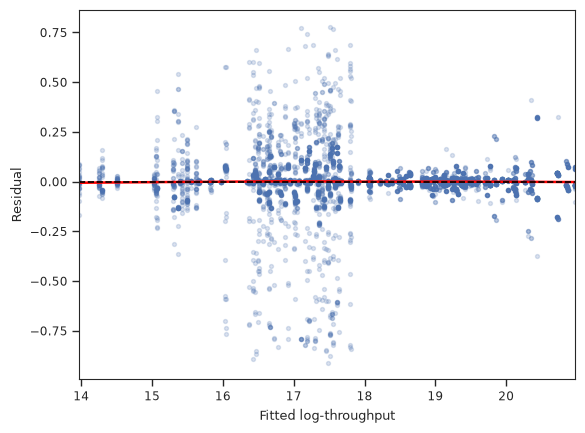

In [20]:
# Objective: Check residual variance across fitted values.
# Reason: Unequal residual spread requires robust inference.
# Ideally, residuals form a roughly constant-width band around zero, 
# with the red line approximately horizontal.
sns.residplot(
    x=full_model.fittedvalues,
    y=full_model.resid,
    lowess=True,
    scatter_kws={"alpha": 0.2, "s": 8},
    line_kws={"color": "red"}
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Fitted log-throughput")
plt.ylabel("Residual")
plt.show()

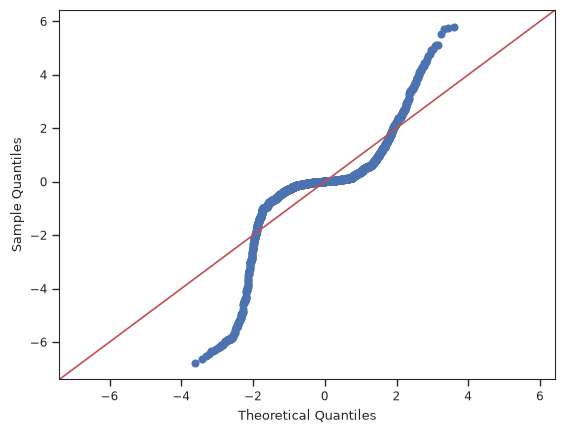

In [21]:
# Objective: Check residual normality and extreme tails.
# Reason: Strong departures may require robust inference even when residual spread looks stable.
# The points should approximately follow the reference line.
# Small deviations at the ends are usually acceptable.
sm.qqplot(
    full_model.resid,
    line="45",
    fit=True
)

plt.show()